# Ion yields vs pump–probe delay — AcH delay scans

Is the ion yield, or the share of some ion fragments, delay dependent? How do the ion yields scale with pulse energy
at each delay, and which ions come together with fast electrons (valence photoelectrons and Auger electrons)?

**Data.** Time-resolved aggregates (`*_aggregates_tr.h5`, `compute_aggregates.py`, config 1) of the AcH delay scans:
per cell (GMD bin × delay bin) the mean electron and ion TOF histograms `D`, `C`, their second moments (`CtC`, `DtC`,
…), GMD `G`, `GtG`, the VLS spectrum `A` and its products, and the number of shots `n`. Each scan was processed with
`~/slurm_delayscan.sh RUN MEASUREMENT CONFIG`:

```
python write_h5.py <measurement> 1 <run> --live --live-margin 0 --max-ecounts 120 --max-icounts 50 -o <measurement>.h5
python analysis/scripts/compute_aggregates.py analysis/configs/aggregates_ethanol_delay[_longscans].py <measurement>.h5
python analysis/scripts/compute_ready_counts.py <measurement>_aggregates_tr.h5
```
(long scans: 32 delay bins of 2.0 fs, −4.9 to 59.3 fs; short scans: 31 bins of 0.99 fs, ±15.4 fs.)

**Steps.**
1. Load the scans in `SCANS` and reduce each file to the moments needed below.
2. Ion yield of each m/q range per `MONITOR` against delay, and the fraction of all ions (independent of the monitor),
   each relative to its delay average; per scan for reproducibility.
3. Power law $Y \propto X^p$ over the GMD bins at every delay, for the yields and the fractions.
4. Ions in coincidence with fast electrons (`E_WINDOWS`): the partial covariance on GMD of the electron count in a
   window with the ion spectrum, per detected electron; its m/q distribution and its delay dependence.
5. The fractions and the yield per monitor against delay for every photon energy in `ENERGY_SCANS`.

**Notes.**
- Errors of means, yields, fractions and $p$ come from the stored second moments (exact for the aggregated shots).
  The covariances of section 4 would need fourth moments; their errors are the spread between scans (standard error
  of the mean over the scans), so they need several scans.
- GMD bins are percentiles of each scan; scans are pooled bin by bin, so a pooled GMD bin mixes slightly different
  intervals (the fits use the pooled ⟨G⟩ of each cell).
- Ion hits are not corrected for dead time. The electron counts in section 4 are recorded counts (dead time cannot be
  corrected in covariances); the partial covariance removes the part of the correlation linear in GMD within a cell.
- m/q uses `calibration.py` (argon run 60538); `MQ_CAL` replaces it. Delay: `DELAY_SIGN·(z − Z_ZERO)·FS_PER_Z`, as in
  the colleagues' delay notebooks; time zero is not established.
- Each scan sweeps the delay once at constant speed (a long scan −4.9 → 59.3 fs in ~42 min), so within a scan delay and
  acquisition time are the same axis: a drift during a scan (gas density, monitor) looks like a delay dependence. A
  delay effect has to reproduce in every scan; section 2 compares the scans (χ²/dof of each scan against the pooled
  curve).

In [1]:
# ---- Parameters ---------------------------------------------------------------
SCANS = "AcH_long_delay_scan_*_271.2eV_*_aggregates_tr.h5"   # glob in config.COMBINED_DIR; pooled, same delay bins
EXCLUDE = []                 # file names left out
DELAY_SIGN, Z_ZERO, FS_PER_Z = 1, 0.0, 0.349 / 1000           # delay (fs) = DELAY_SIGN * (z - Z_ZERO) * FS_PER_Z

# ion m/q ranges: name -> (lo, hi); a 10 ns TOF bin counts when its centre falls inside
MQ_RANGES = {
    "1":     (0.3, 1.6),
    "2":     (1.6, 2.6),
    "12-16": (11.5, 16.5),
    "17-19": (16.5, 19.5),
    "20-22": (19.5, 22.5),
    "24-27": (23.5, 27.5),
    "28-31": (27.5, 31.5),
    "32-36": (31.5, 36.5),
    "41-44": (40.5, 44.5),
    "45-49": (44.5, 49.5),
}
TOTAL_MQ = (0.3, 50)         # "all ions"
MONITOR = "vls"              # yields are divided by: "vls" (VLS line sum, 10^4 ADU), "gmd" (µJ) or "shot"
P_MONITOR = "gmd"            # x of the power-law fits: "gmd" or "vls"
MIN_SHOTS = 300              # cells with fewer shots are left out of the fits
MIN_GMD_BINS = 3             # a delay needs this many such GMD bins for a fit

# fast electrons: ("BE", lo, hi) = binding-energy window (photon energy from the file name), ("KE", lo, hi) = fixed KE
E_WINDOWS = {"valence": ("BE", 8, 20), "Auger": ("KE", 225, 241)}
COINC_RANGES = None          # ion ranges in the coincidence-vs-delay plot; None = all
STACK = {"yield": 0.08, "p": 0.05, "coinc": 1.5}   # vertical offsets between stacked curves (0: overlaid)

ENERGY_SCANS = {f"{e} eV": f"AcH_long_delay_scan_*_{e}eV_*_aggregates_tr.h5"
                for e in ("268.2", "269.7", "271.2", "272.7", "274.2")}   # section 5
MQ_CAL = None                # (t0_ns, k_ns) replacing calibration.ITOF in t = t0 + k sqrt(m/q)

In [2]:
# ---- Imports, paths, helpers ------------------------------------------------
from pathlib import Path
import re
import sys
import warnings

import h5py
import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import calibration
import config

for msg in ("invalid value encountered", "divide by zero", "Mean of empty slice", "All-NaN slice",
            "Degrees of freedom"):
    warnings.filterwarnings("ignore", message=msg)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

t0_cal, k_cal = MQ_CAL if MQ_CAL is not None else (calibration.ITOF["t0"], calibration.ITOF["k"])
tof_of = lambda mq: t0_cal + k_cal * np.sqrt(mq)                     # ns
mq_of = lambda t: ((np.asarray(t, float) - t0_cal) / k_cal) ** 2
names = list(MQ_RANGES) + ["all ions"]                               # ion ranges; then GMD and VLS as extra quantities
R = len(names)
i_all, i_gmd, i_vls = R - 1, R, R + 1
REDUCED = {}                                                          # file name -> reduced moments


def reduce_file(path):
    # First and second moments per cell (GMD bin, delay bin) of [ion ranges, all ions, GMD, VLS line sum], and the
    # moments of each fast-electron window with GMD and with the ion spectrum.
    hv = float(re.search(r"_(\d+(?:\.\d+)?)eV_", path.name).group(1))
    with h5py.File(path, "r") as f:
        n, G, GtG = f["n_per_bin"][...], f["G"][...], f["GtG"][...]
        z_edges, gmd_edges = f["z_edges"][...], f["gmd_edges"][...]
        ie = f["ion_tof_edges"][...] / 10.0                           # TDC units (100 ps) -> ns
        ee = f["tof_edges"][...] / 10.0
        C, CtC, CtG = f["C"][...], f["CtC"][...], f["CtG"][...]
        V = f["A"][...].sum(-1) / 1e4                                 # VLS line sum (10^4 ADU)
        VtV = f["AtA"][...].sum((-2, -1)) / 1e8
        VtC = f["AtC"][...].sum(-2) / 1e4
        VtG = f["AtG"][...].sum(-1) / 1e4
        D, DtG, DtC = f["D"][...], f["DtG"][...], f["DtC"][...]
    tof_i = 0.5 * (ie[1:] + ie[:-1])
    Wi = np.zeros((R, len(tof_i)))
    for i, (lo, hi) in enumerate(list(MQ_RANGES.values()) + [TOTAL_MQ]):
        Wi[i, (tof_i >= tof_of(lo)) & (tof_i < tof_of(hi))] = 1
    ke = calibration.ke_of_tof(0.5 * (ee[1:] + ee[:-1]))
    We = np.zeros((len(E_WINDOWS), len(ke)))
    for w, (kind, lo, hi) in enumerate(E_WINDOWS.values()):
        k_lo, k_hi = (hv - hi, hv - lo) if kind == "BE" else (lo, hi)
        We[w, (ke >= k_lo) & (ke < k_hi)] = 1
    Y = np.concatenate([np.einsum("rt,gzt->rgz", Wi, C), G[None], V[None]])
    M2 = np.zeros((R + 2, R + 2) + G.shape)
    M2[:R, :R] = np.einsum("rt,gztq->rqgz", Wi, CtC @ Wi.T)
    M2[:R, i_gmd] = M2[i_gmd, :R] = np.einsum("rt,gzt->rgz", Wi, CtG)
    M2[:R, i_vls] = M2[i_vls, :R] = np.einsum("rt,gzt->rgz", Wi, VtC)
    M2[i_gmd, i_gmd], M2[i_vls, i_vls] = GtG, VtV
    M2[i_gmd, i_vls] = M2[i_vls, i_gmd] = VtG
    return dict(file=path.name, hv=hv, n=n, z_edges=z_edges, gmd_edges=gmd_edges, tof_i=tof_i, Wi=Wi, Y=Y, M2=M2,
                C=C, CtG=CtG, G=G, GtG=GtG, Ne=np.einsum("wt,gzt->wgz", We, D),
                NeG=np.einsum("wt,gzt->wgz", We, DtG), NeC=np.einsum("wt,gztc->wgzc", We, DtC),
                ke_windows=[(hv - hi, hv - lo) if k == "BE" else (lo, hi) for k, lo, hi in E_WINDOWS.values()])


def load_set(pattern):
    # reduce (once) and stack the scans matching `pattern`; their delay bins must be identical
    files = [p for p in sorted(config.COMBINED_DIR.glob(pattern)) if p.name not in EXCLUDE]
    if not files:
        raise FileNotFoundError(f"no files for {pattern}")
    for p in files:
        if p.name not in REDUCED:
            REDUCED[p.name] = reduce_file(p)
    red = [REDUCED[p.name] for p in files]
    for r in red[1:]:
        if not np.array_equal(r["z_edges"], red[0]["z_edges"]) or r["n"].shape != red[0]["n"].shape:
            raise ValueError(f"{r['file']}: delay bins differ from {red[0]['file']}")
    d = {k: np.stack([r[k] for r in red]) for k in ("n", "Y", "M2", "C", "CtG", "G", "GtG", "Ne", "NeG", "NeC")}
    z = 0.5 * (red[0]["z_edges"][1:] + red[0]["z_edges"][:-1])
    d.update(files=[r["file"] for r in red], hv=sorted({r["hv"] for r in red}), delay=DELAY_SIGN * (z - Z_ZERO) * FS_PER_Z,
             tof_i=red[0]["tof_i"], Wi=red[0]["Wi"], ke_windows=red[0]["ke_windows"])
    return d


def delay_moments(d):
    # means Y and per-shot covariances S of all quantities per delay (scans and GMD bins pooled), and over all delays
    n = d["n"]                                                        # (scan, gmd, delay)
    nz = n.sum(axis=(0, 1))
    Yz = np.nansum(d["Y"] * n[:, None], axis=(0, 2)) / nz              # (Q, delay)
    Sz = np.nansum(d["M2"] * n[:, None, None], axis=(0, 3)) / nz - Yz[:, None] * Yz[None]
    na = nz.sum()
    Ya = np.nansum(d["Y"] * n[:, None], axis=(0, 2, 3)) / na
    Sa = np.nansum(d["M2"] * n[:, None, None], axis=(0, 3, 4)) / na - Ya[:, None] * Ya[None]
    return Yz, Sz, nz, Ya, Sa, na


def ratio(i, j, Y, S, n):
    # Y[i] / Y[j] and its error, from the per-shot (co)variances S over n shots
    r = Y[i] / Y[j]
    return r, np.abs(r) * np.sqrt((S[i, i] / Y[i] ** 2 + S[j, j] / Y[j] ** 2 - 2 * S[i, j] / (Y[i] * Y[j])) / n)


def per_monitor(i, Y, S, n):
    # yield of quantity i per MONITOR (per shot for "shot")
    if MONITOR == "shot":
        return Y[i], np.sqrt(S[i, i] / n)
    return ratio(i, {"gmd": i_gmd, "vls": i_vls}[MONITOR], Y, S, n)


def power_law(x, y, e):
    # p and its error from a weighted straight line through log y against log x
    ok = (y > 0) & (x > 0) & np.isfinite(e) & (e > 0)
    if ok.sum() < MIN_GMD_BINS:
        return np.nan, np.nan
    c, cov = np.polyfit(np.log(x[ok]), np.log(y[ok]), 1, w=y[ok] / e[ok], cov="unscaled")
    return c[0], np.sqrt(cov[0, 0])


def chi2_const(y, e):
    # chi2 / dof of y against its weighted mean
    ok = np.isfinite(y) & np.isfinite(e) & (e > 0)
    w = 1 / e[ok] ** 2
    return np.sum(w * (y[ok] - np.sum(w * y[ok]) / np.sum(w)) ** 2) / max(ok.sum() - 1, 1)

def scale_bar(ax, x, size, label):
    # vertical bar of `size` in y units, from the baseline of the lowest curve
    ax.plot([x, x], [1, 1 + size] if label.endswith("%") else [0, size], color="k", lw=2)
    ax.text(x - 0.6, (1 if label.endswith("%") else 0) + size / 2, label, ha="right", va="center", fontsize=8)


## 1. Load

In [3]:
d = load_set(SCANS)
delay, n = d["delay"], d["n"]
Yz, Sz, nz, Ya, Sa, na = delay_moments(d)
print(f"{len(d['files'])} scans, photon energy {d['hv']} eV, {n.sum()} shots, {len(delay)} delay bins "
      f"{delay[0]:.2f} .. {delay[-1]:.2f} fs ({np.diff(delay).mean():.3f} fs/bin)")
for f_, ns in zip(d["files"], n.sum(axis=(1, 2))):
    print(f"  {f_}: {ns} shots")
print(f"shots per delay bin: {nz.min()} .. {nz.max()}; {Ya[i_all]:.3f} ions / shot in {TOTAL_MQ}, "
      f"<G> {Ya[i_gmd]:.3f} µJ, <VLS> {Ya[i_vls]:.3f} x 10^4 ADU")
print("fast-electron windows (KE, eV): " + ", ".join(f"{k} {lo:.1f}-{hi:.1f}" for k, (lo, hi) in zip(E_WINDOWS, d["ke_windows"])))

4 scans, photon energy [271.2] eV, 9845664 shots, 32 delay bins -3.89 .. 58.33 fs (2.007 fs/bin)
  AcH_long_delay_scan_1_271.2eV_2810422621_aggregates_tr.h5: 2453617 shots
  AcH_long_delay_scan_2_271.2eV_2810449226_aggregates_tr.h5: 2460433 shots
  AcH_long_delay_scan_3_271.2eV_2810475158_aggregates_tr.h5: 2465878 shots
  AcH_long_delay_scan_4_271.2eV_2810501260_aggregates_tr.h5: 2465736 shots
shots per delay bin: 305453 .. 308700; 0.551 ions / shot in (0.3, 50), <G> 0.386 µJ, <VLS> 0.719 x 10^4 ADU
fast-electron windows (KE, eV): valence 251.2-263.2, Auger 225.0-241.0


## 2. Ion yield against delay
Left: yield of each range per `MONITOR`; right: fraction of all ions (no monitor). Both are divided by their value
over all delays, so a delay dependence shows on a linear scale around 1. χ²/dof is for a curve constant in delay. The
second figure shows each scan; the table under it gives χ²/dof of the scans against the pooled curve (about 1 when the
scans agree within their errors; a drift during the scans makes it large).

 range           per vls (all delays)   chi2/dof   max |dev|      fraction (all delays)   chi2/dof   max |dev|
 1                0.0401               1.54      0.027      0.0523                    1.24      0.024
 2                0.0092               0.62      0.037      0.0121                    0.63      0.042
 12-16            0.0905               2.87      0.030      0.1181                    1.19      0.013
 17-19            0.0438               1.88      0.030      0.0572                    1.06      0.029
 20-22            0.1023               2.26      0.023      0.1336                    0.71      0.014
 24-27            0.0558               3.02      0.035      0.0728                    1.29      0.019
 28-31            0.1691               4.52      0.020      0.2208                    1.03      0.010
 32-36            0.1171               3.05      0.027      0.1529                    1.09      0.013
 41-44            0.0270               1.13      0.035      0.0353       

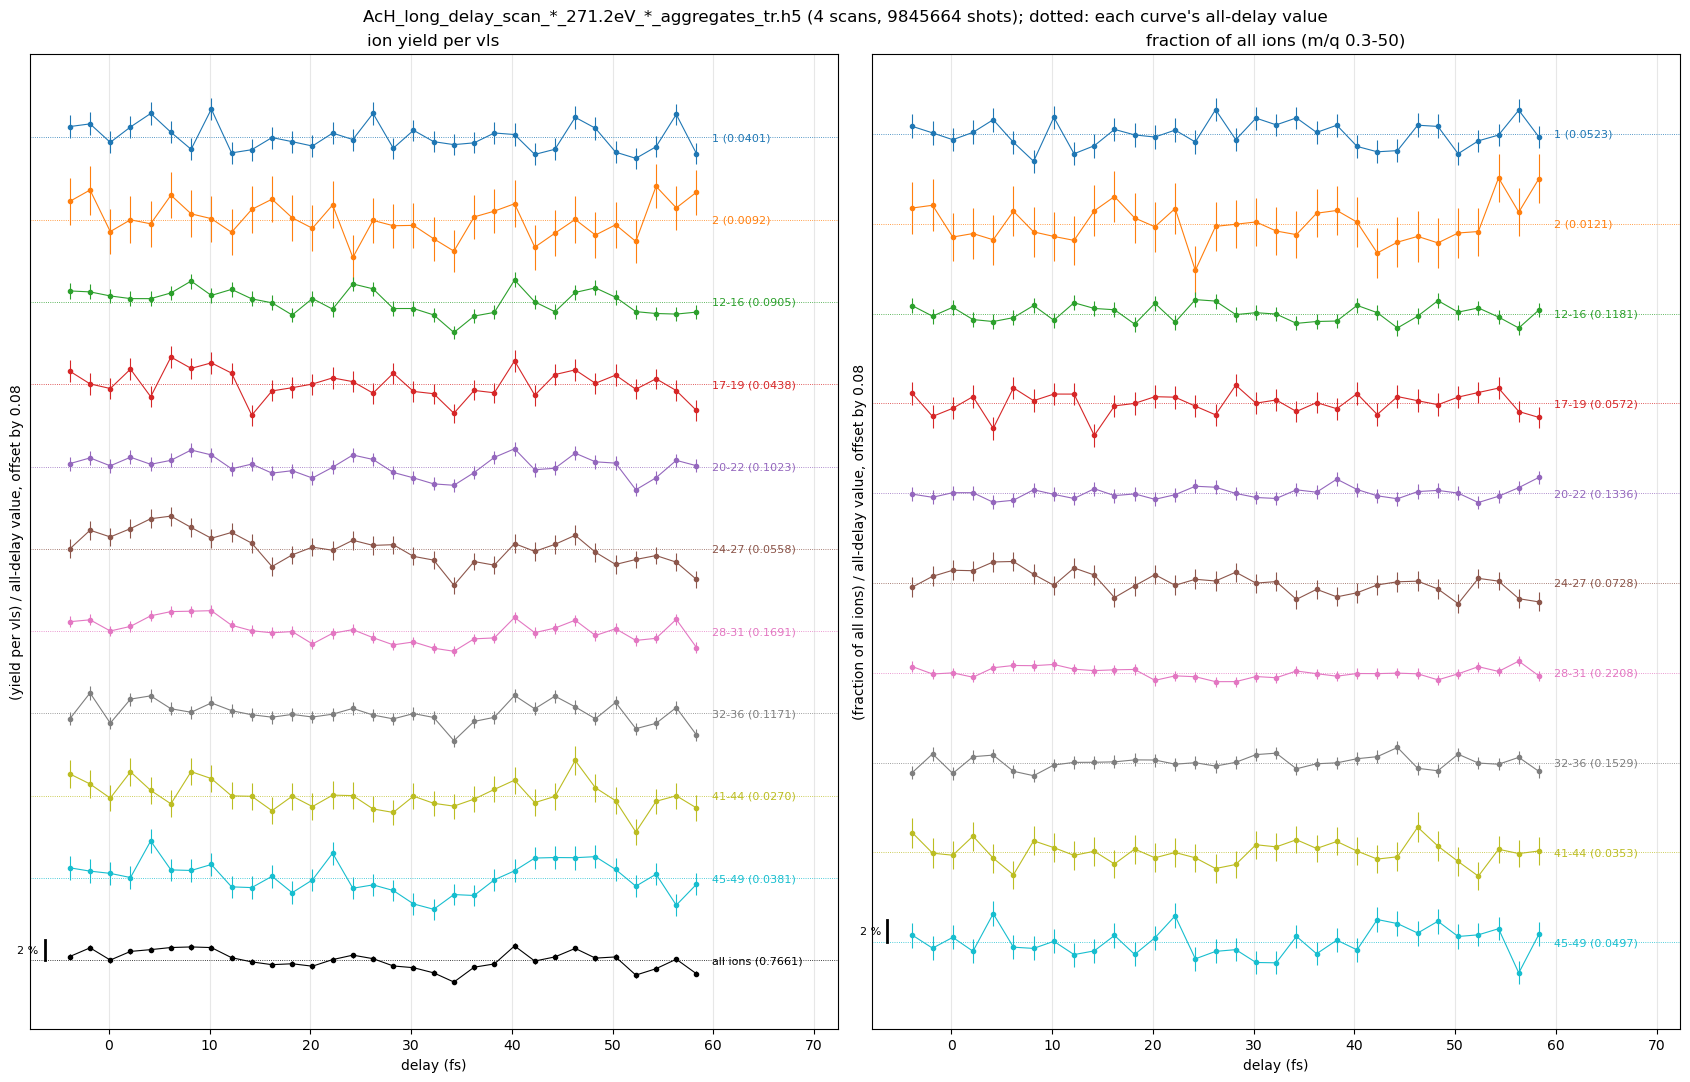

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(17, 11))
step = STACK["yield"]
print(f" range      {'per ' + MONITOR:>12s} (all delays)   chi2/dof   max |dev|      fraction (all delays)   chi2/dof   max |dev|")
for i in range(R):
    col = f"C{i % 10}" if i < i_all else "k"
    y, e = per_monitor(i, Yz, Sz, nz)
    y0 = per_monitor(i, Ya, Sa, na)[0]
    off = (R - 1 - i) * step                                     # first range on top
    axs[0].errorbar(delay, y / y0 + off, e / y0, fmt="o-", ms=3, lw=0.8, color=col)
    axs[0].axhline(1 + off, color=col, lw=0.6, ls=":")
    axs[0].text(delay[-1] + 1.5, 1 + off, f"{names[i]} ({y0:.4f})", color=col, va="center", fontsize=8)
    line = f" {names[i]:9s}  {y0:12.4f}            {chi2_const(y, e):7.2f}   {np.nanmax(np.abs(y / y0 - 1)):8.3f}"
    if i != i_all:
        f_, fe = ratio(i, i_all, Yz, Sz, nz)
        f0 = Ya[i] / Ya[i_all]
        off = (R - 2 - i) * step
        axs[1].errorbar(delay, f_ / f0 + off, fe / f0, fmt="o-", ms=3, lw=0.8, color=col)
        axs[1].axhline(1 + off, color=col, lw=0.6, ls=":")
        axs[1].text(delay[-1] + 1.5, 1 + off, f"{names[i]} ({f0:.4f})", color=col, va="center", fontsize=8)
        line += f"      {f0:.4f}                 {chi2_const(f_, fe):7.2f}   {np.nanmax(np.abs(f_ / f0 - 1)):8.3f}"
    print(line)
axs[0].set(ylabel=f"(yield per {MONITOR}) / all-delay value, offset by {step}", title=f"ion yield per {MONITOR}")
axs[1].set(ylabel=f"(fraction of all ions) / all-delay value, offset by {step}",
           title=f"fraction of all ions (m/q {TOTAL_MQ[0]}-{TOTAL_MQ[1]})")
for ax in axs:
    ax.set(xlabel="delay (fs)", xlim=(delay[0] - 4, delay[-1] + 14), yticks=[])
    scale_bar(ax, delay[0] - 2.5, 0.02, "2 %")
fig.suptitle(f"{SCANS} ({len(d['files'])} scans, {n.sum()} shots); dotted: each curve's all-delay value")
fig.tight_layout()
plt.show()

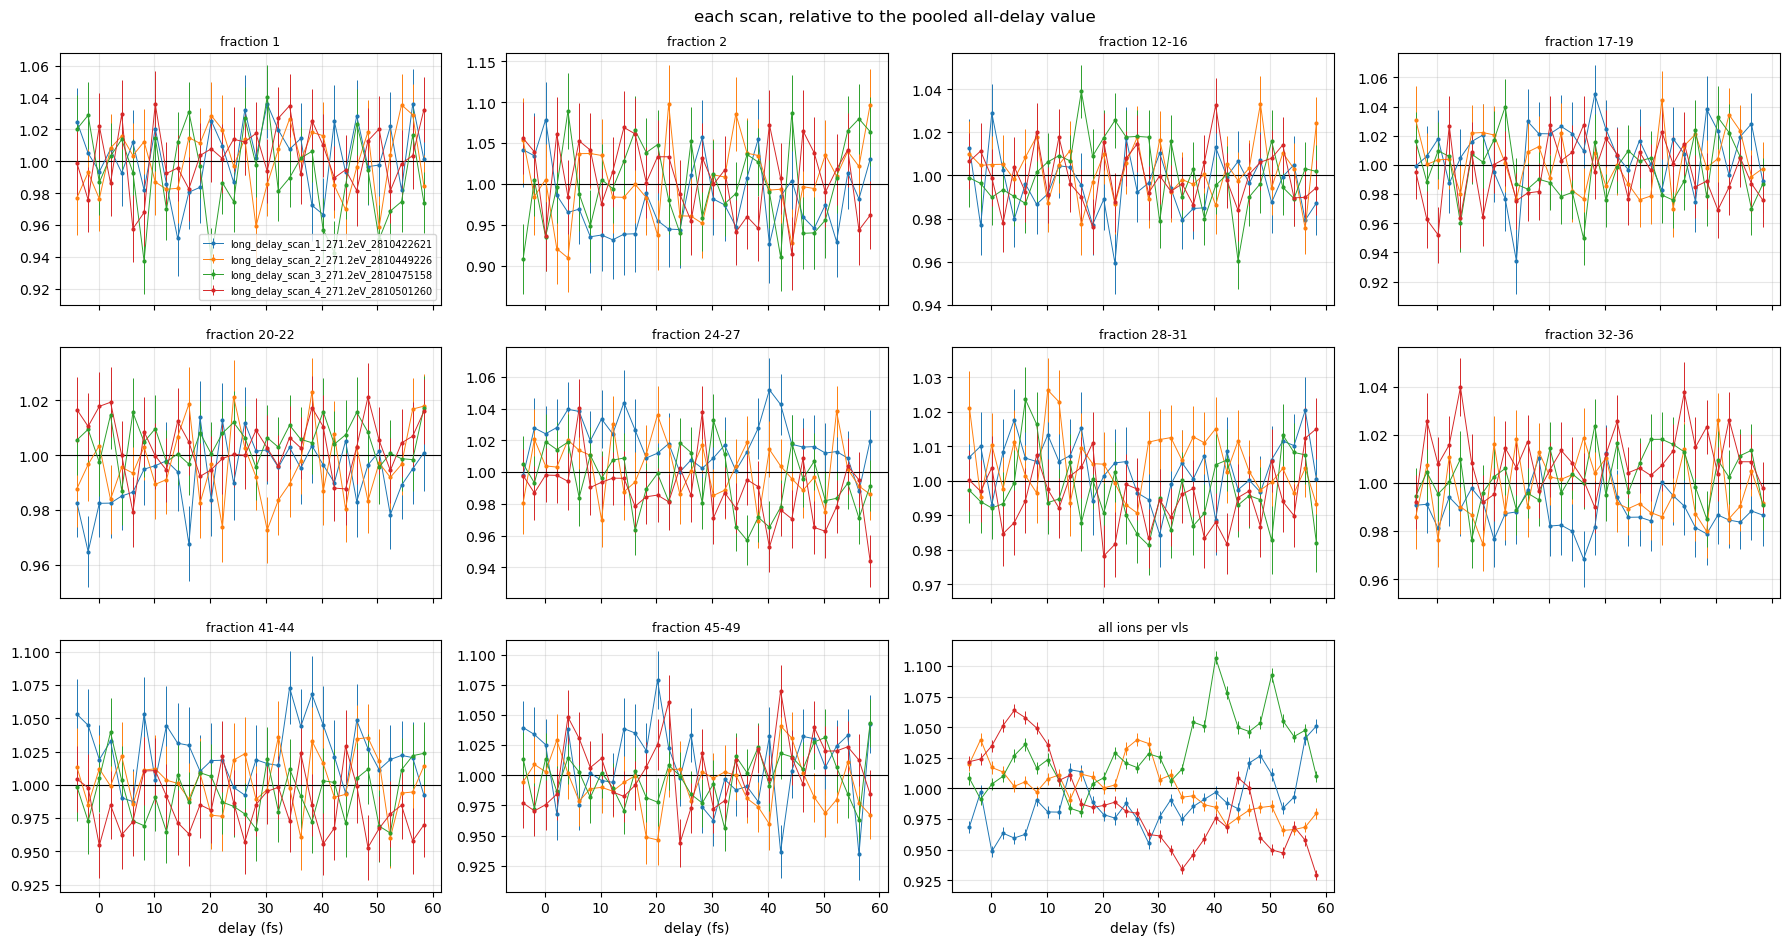

 quantity                  chi2/dof of the scans against the pooled curve
 fraction 1                    1.21
 fraction 2                    1.32
 fraction 12-16                1.10
 fraction 17-19                1.14
 fraction 20-22                0.94
 fraction 24-27                1.58
 fraction 28-31                1.30
 fraction 32-36                1.55
 fraction 41-44                1.11
 fraction 45-49                1.57
 all ions per vls             54.12


In [5]:
# Reproducibility: each scan separately (fraction of all ions per range; last panel: all ions per MONITOR)
ncol = 4
fig, axs = plt.subplots(int(np.ceil(R / ncol)), ncol, figsize=(18, 3.2 * np.ceil(R / ncol)), sharex=True, squeeze=False)
ys = np.full((len(d["files"]), R, len(delay)), np.nan)          # each scan, relative to the pooled all-delay value
es = np.full_like(ys, np.nan)
for s, f_name in enumerate(d["files"]):
    ns = n[s].sum(axis=0)
    Ys = np.nansum(d["Y"][s] * n[s][None], axis=1) / ns
    Ss = np.nansum(d["M2"][s] * n[s][None, None], axis=2) / ns - Ys[:, None] * Ys[None]
    for i, ax in zip(range(R), axs.flat):
        if i == i_all:
            y, e = per_monitor(i, Ys, Ss, ns)
            y0 = per_monitor(i, Ya, Sa, na)[0]
        else:
            y, e = ratio(i, i_all, Ys, Ss, ns)
            y0 = Ya[i] / Ya[i_all]
        ys[s, i], es[s, i] = y / y0, e / y0
        ax.errorbar(delay, y / y0, e / y0, fmt="o-", ms=2, lw=0.7, color=f"C{s}",
                    label=f_name.split("_aggregates")[0].replace("AcH_", "") if i == 0 else None)
for i, ax in zip(range(R), axs.flat):
    ax.axhline(1, color="k", lw=0.8)
    ax.set_title(f"all ions per {MONITOR}" if i == i_all else f"fraction {names[i]}", fontsize=9)
for ax in axs.flat[R:]:
    ax.set_visible(False)
axs.flat[0].legend(fontsize=7)
for ax in axs[-1]:
    ax.set_xlabel("delay (fs)")
fig.suptitle("each scan, relative to the pooled all-delay value")
fig.tight_layout()
plt.show()

print(" quantity                  chi2/dof of the scans against the pooled curve")
for i in range(R):
    if i == i_all:
        yp = per_monitor(i, Yz, Sz, nz)[0] / per_monitor(i, Ya, Sa, na)[0]
        lab = f"all ions per {MONITOR}"
    else:
        yp = ratio(i, i_all, Yz, Sz, nz)[0] / (Ya[i] / Ya[i_all])
        lab = f"fraction {names[i]}"
    ok = np.isfinite(ys[:, i]) & (es[:, i] > 0)
    print(f" {lab:24s}  {np.sum(((ys[:, i] - yp) / es[:, i])[ok] ** 2) / max(ok.sum() - len(delay), 1):8.2f}")

## 3. Power law against delay
At every delay the GMD bins (scans pooled bin by bin) give $p$ in $Y \propto X^p$ with $X$ = `P_MONITOR`, for the yield of
each range and for its fraction of all ions ($p$ of the fraction = difference of the two orders).

 range      p yield (weighted mean)   chi2/dof      p fraction (weighted mean)   chi2/dof
 1             0.905 ± 0.003            1.74       -0.012 ± 0.002            1.54   
 2             0.890 ± 0.005            0.90       -0.026 ± 0.005            0.86   
 12-16         0.923 ± 0.002            1.70        0.005 ± 0.002            1.38   
 17-19         0.922 ± 0.002            1.12        0.004 ± 0.002            0.99   
 20-22         0.926 ± 0.002            1.01        0.008 ± 0.001            0.96   
 24-27         0.922 ± 0.002            0.85        0.004 ± 0.002            0.78   
 28-31         0.919 ± 0.001            1.43        0.002 ± 0.001            1.00   
 32-36         0.917 ± 0.001            0.86        0.000 ± 0.001            0.47   
 41-44         0.914 ± 0.003            1.21       -0.004 ± 0.003            0.99   
 45-49         0.914 ± 0.003            0.68       -0.004 ± 0.003            0.68   
 all ions      0.916 ± 0.001            1.71   


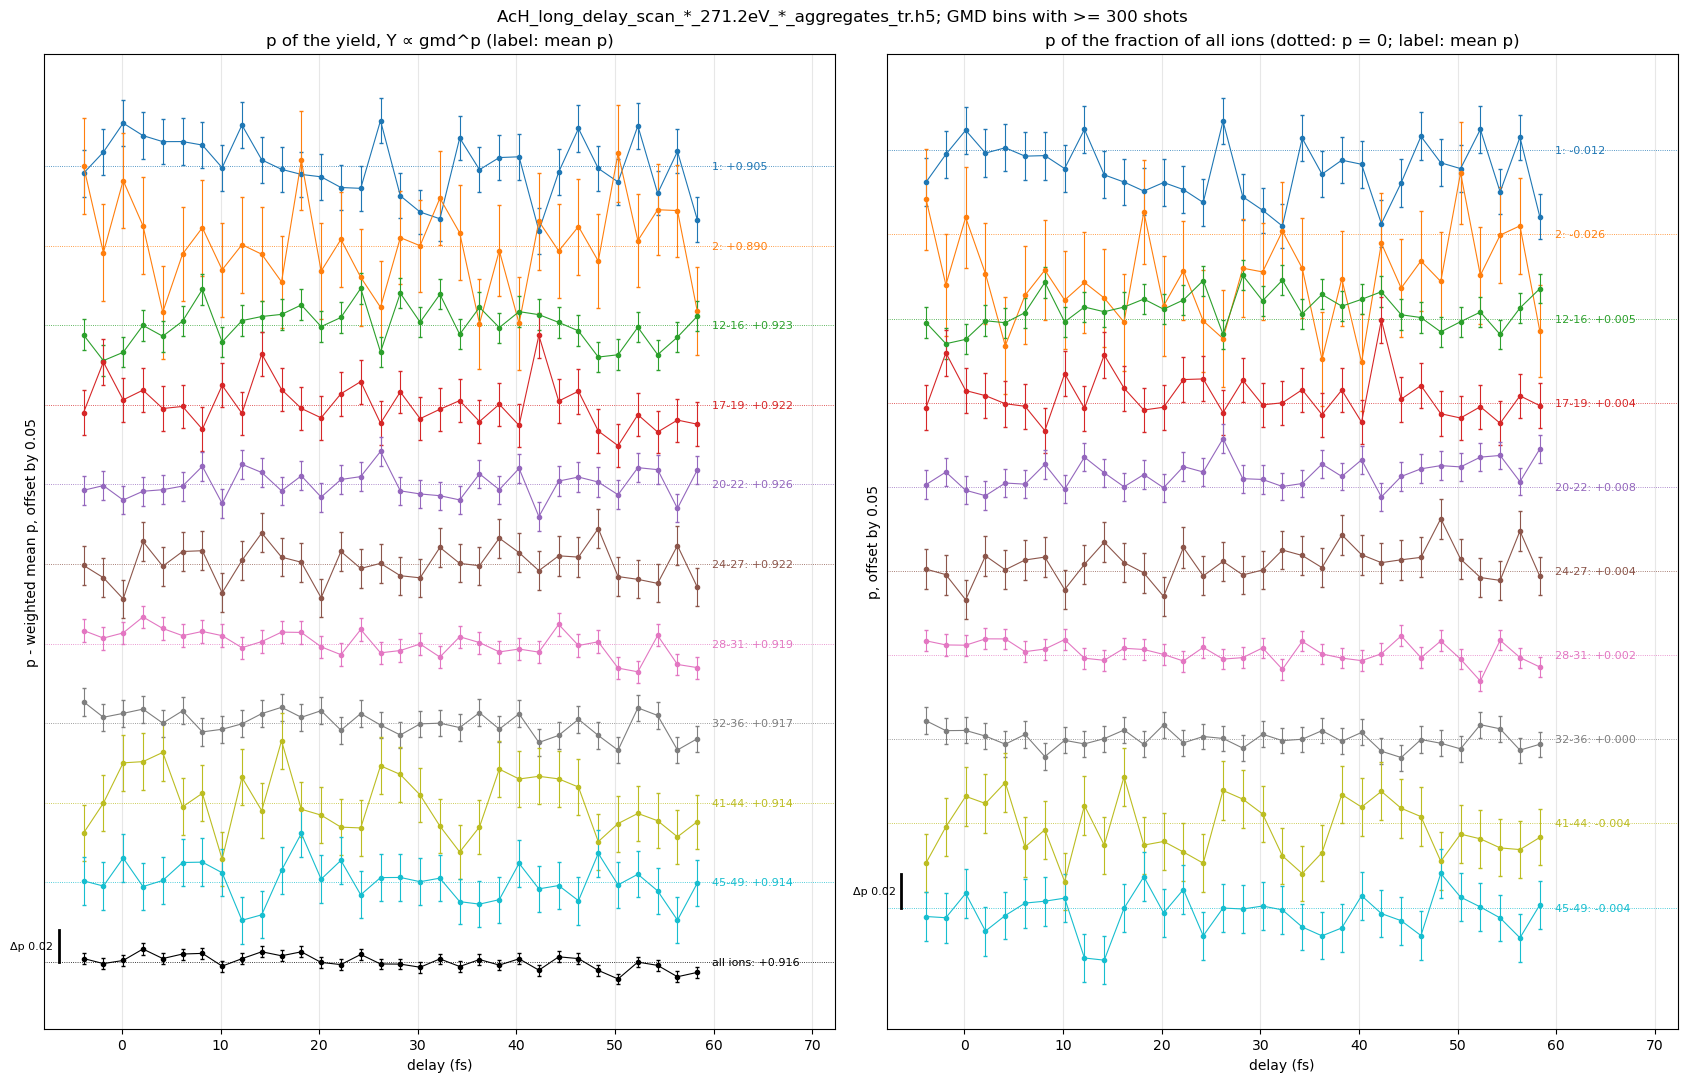

In [6]:
ng = n.sum(axis=0)                                               # (gmd, delay) shots, scans pooled per GMD bin
Yg = np.nansum(d["Y"] * n[:, None], axis=0) / ng                 # (Q, gmd, delay)
Sg = np.nansum(d["M2"] * n[:, None, None], axis=0) / ng - Yg[:, None] * Yg[None]
iP = {"gmd": i_gmd, "vls": i_vls}[P_MONITOR]
P = np.full((2, R, len(delay), 2), np.nan)                       # (yield / fraction, range, delay, [p, err])
for z in range(len(delay)):
    ok = ng[:, z] >= MIN_SHOTS
    x, Yc, Sc, nc = Yg[iP, ok, z], Yg[:, ok, z], Sg[:, :, ok, z], ng[ok, z]
    for i in range(R):
        P[0, i, z] = power_law(x, Yc[i], np.sqrt(Sc[i, i] / nc))
        if i != i_all:
            P[1, i, z] = power_law(x, *ratio(i, i_all, Yc, Sc, nc))

step = STACK["p"]
fig, axs = plt.subplots(1, 2, figsize=(17, 11))
print(f" range      p yield (weighted mean)   chi2/dof      p fraction (weighted mean)   chi2/dof")
for i in range(R):
    line = f" {names[i]:9s}"
    col = f"C{i % 10}" if i < i_all else "k"
    for k, ax in enumerate(axs):
        if k == 1 and i == i_all:
            continue
        p, e = P[k, i, :, 0], P[k, i, :, 1]
        ok = np.isfinite(p) & (e > 0)
        pm = np.sum(p[ok] / e[ok] ** 2) / np.sum(1 / e[ok] ** 2)
        off = ((R if k == 0 else R - 1) - 1 - i) * step              # first range on top
        base = pm if k == 0 else 0.0                                 # yields: around their mean; fractions: around 0
        ax.errorbar(delay, p - base + off, e, fmt="o-", ms=3, lw=0.8, capsize=1.5, color=col)
        ax.axhline(off, color=col, lw=0.6, ls=":")
        ax.text(delay[-1] + 1.5, off, f"{names[i]}: {pm:+.3f}", color=col, va="center", fontsize=8)
        line += f"   {pm:7.3f} ± {1 / np.sqrt(np.sum(1 / e[ok] ** 2)):.3f}          {chi2_const(p, e):6.2f}   "
    print(line)
axs[0].set(ylabel=f"p - weighted mean p, offset by {step}", title=f"p of the yield, Y ∝ {P_MONITOR}^p (label: mean p)")
axs[1].set(ylabel=f"p, offset by {step}", title="p of the fraction of all ions (dotted: p = 0; label: mean p)")
for ax in axs:
    ax.set(xlabel="delay (fs)", xlim=(delay[0] - 4, delay[-1] + 14), yticks=[])
    scale_bar(ax, delay[0] - 2.5, 0.02, "Δp 0.02")
fig.suptitle(f"{SCANS}; GMD bins with >= {MIN_SHOTS} shots")
fig.tight_layout()
plt.show()

## 4. Ions in coincidence with fast electrons
Per cell, the partial covariance on GMD of the electron count $N_e$ in each `E_WINDOWS` window with the ion spectrum,
$\mathrm{pCov}(N_e, C) = \mathrm{Cov}(N_e, C) - \mathrm{Cov}(N_e, G)\,\mathrm{Cov}(G, C)/\mathrm{Var}(G)$, averaged over
the cells weighted by shots and divided by $\langle N_e \rangle$: the number of ions correlated with one detected fast
electron, beyond the common dependence on pulse energy. Errors: standard error of the mean over the scans.

<N_e> per shot: valence 0.1159, Auger 0.1177
 range      singles: fraction   valence: ions/e (± scans)   fraction   x singles   Auger: ions/e (± scans)   fraction   x singles
 1            0.0523             +0.0021 ± 0.0001       0.0095     0.18   +0.0120 ± 0.0001       0.1829     3.50
 2            0.0121             +0.0003 ± 0.0000       0.0012     0.10   +0.0032 ± 0.0000       0.0494     4.09
 12-16        0.1181             +0.0157 ± 0.0004       0.0707     0.60   +0.0113 ± 0.0005       0.1720     1.46
 17-19        0.0572             +0.0110 ± 0.0003       0.0496     0.87   +0.0048 ± 0.0003       0.0732     1.28
 20-22        0.1336             +0.0047 ± 0.0001       0.0211     0.16   +0.0040 ± 0.0004       0.0616     0.46
 24-27        0.0728             +0.0223 ± 0.0004       0.1006     1.38   +0.0044 ± 0.0003       0.0667     0.92
 28-31        0.2208             +0.0786 ± 0.0008       0.3546     1.61   +0.0074 ± 0.0003       0.1133     0.51
 32-36        0.1529             +

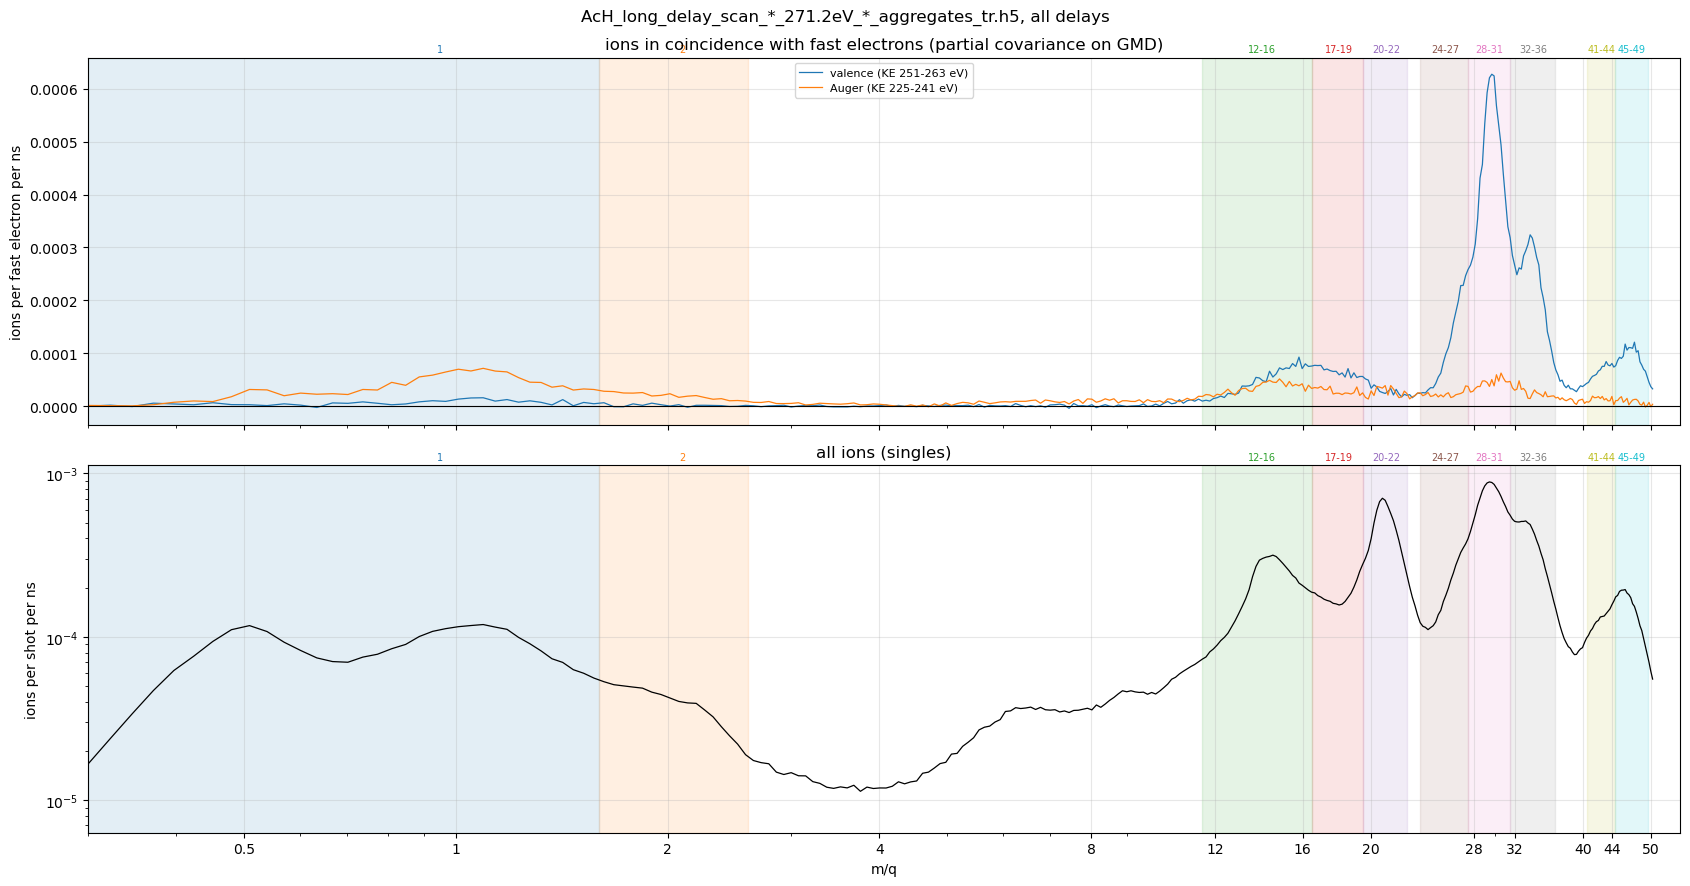

In [7]:
nW = len(E_WINDOWS)
C_, G_, GtG_, Ne, NeG, NeC, CtG_ = (d[k] for k in ("C", "G", "GtG", "Ne", "NeG", "NeC", "CtG"))
pcov = ((NeC - Ne[..., None] * C_[:, None])
        - (NeG - Ne * G_[:, None])[..., None] * (CtG_ - C_ * G_[..., None])[:, None]
        / (GtG_ - G_ ** 2)[:, None, :, :, None])                  # (scan, window, gmd, delay, ion TOF bin)
w8 = n[:, None, :, :, None]
pc_a = np.nansum(pcov * w8, axis=(0, 2, 3)) / na                 # (window, ion TOF bin), all delays
Ne_a = np.nansum(Ne * n[:, None], axis=(0, 2, 3)) / na           # (window,)
per_e = pc_a / Ne_a[:, None]                                     # coincident ions per detected fast electron
Wi = d["Wi"]
rng_e = per_e @ Wi.T                                             # (window, range)
# the same per scan, for the errors
pc_s = np.nansum(pcov * w8, axis=(2, 3)) / n.sum(axis=(1, 2))[:, None, None]
Ne_s = np.nansum(Ne * n[:, None], axis=(2, 3)) / n.sum(axis=(1, 2))[:, None]
rng_s = (pc_s / Ne_s[..., None]) @ Wi.T                          # (scan, window, range)
rng_err = rng_s.std(axis=0, ddof=1) / np.sqrt(len(d["files"])) if len(d["files"]) > 1 else np.full(rng_e.shape, np.nan)

f_single = Ya[:R] / Ya[i_all]
print(f"<N_e> per shot: " + ", ".join(f"{k} {v:.4f}" for k, v in zip(E_WINDOWS, Ne_a)))
print(" range      singles: fraction   " + "   ".join(f"{k}: ions/e (± scans)   fraction   x singles" for k in E_WINDOWS))
for i in range(R):
    line = f" {names[i]:9s}  {f_single[i]:8.4f}          "
    for w in range(nW):
        fc = rng_e[w, i] / rng_e[w, i_all]
        line += f"   {rng_e[w, i]:+.4f} ± {rng_err[w, i]:.4f}      {fc:7.4f}   {fc / f_single[i]:6.2f}"
    print(line)

mq = mq_of(d["tof_i"])
fig, axs = plt.subplots(2, 1, figsize=(17, 9), sharex=True)
for w, k in enumerate(E_WINDOWS):
    axs[0].plot(mq, per_e[w] / 10, lw=0.9, label=f"{k} (KE {d['ke_windows'][w][0]:.0f}-{d['ke_windows'][w][1]:.0f} eV)")
axs[0].axhline(0, color="k", lw=0.8)
axs[0].set(ylabel="ions per fast electron per ns", title="ions in coincidence with fast electrons (partial covariance on GMD)")
axs[1].plot(mq, (np.nansum(C_ * n[..., None], axis=(0, 1, 2)) / na) / 10, color="k", lw=0.9)
axs[1].set(yscale="log", ylabel="ions per shot per ns", title="all ions (singles)", xlabel="m/q")
for ax in axs:
    for i, (lo, hi) in enumerate(MQ_RANGES.values()):
        ax.axvspan(lo, hi, color=f"C{i % 10}", alpha=0.12)
        ax.text(0.5 * (lo + hi), 1.01, names[i], color=f"C{i % 10}", ha="center", va="bottom", fontsize=7,
                transform=ax.get_xaxis_transform())
    ax.set_xscale("log")
    ax.set_xticks([0.5, 1, 2, 4, 8, 12, 16, 20, 28, 32, 40, 44, 50],
                  ["0.5", "1", "2", "4", "8", "12", "16", "20", "28", "32", "40", "44", "50"])
    ax.set_xlim(0.3, 55)
axs[0].legend(fontsize=8)
fig.suptitle(f"{SCANS}, all delays")
fig.tight_layout()
plt.show()

 range      valence: chi2/dof vs constant   Auger: chi2/dof vs constant
 1               1.88                        2.15                 
 2               2.92                        2.86                 
 12-16           0.87                        1.91                 
 17-19           1.53                        1.39                 
 20-22           2.45                        3.10                 
 24-27           5.69                        4.63                 
 28-31           2.45                        0.94                 
 32-36           3.13                        1.35                 
 41-44           4.24                        4.29                 
 45-49           2.08                        2.06                 
 all ions        1.87                        1.29                 


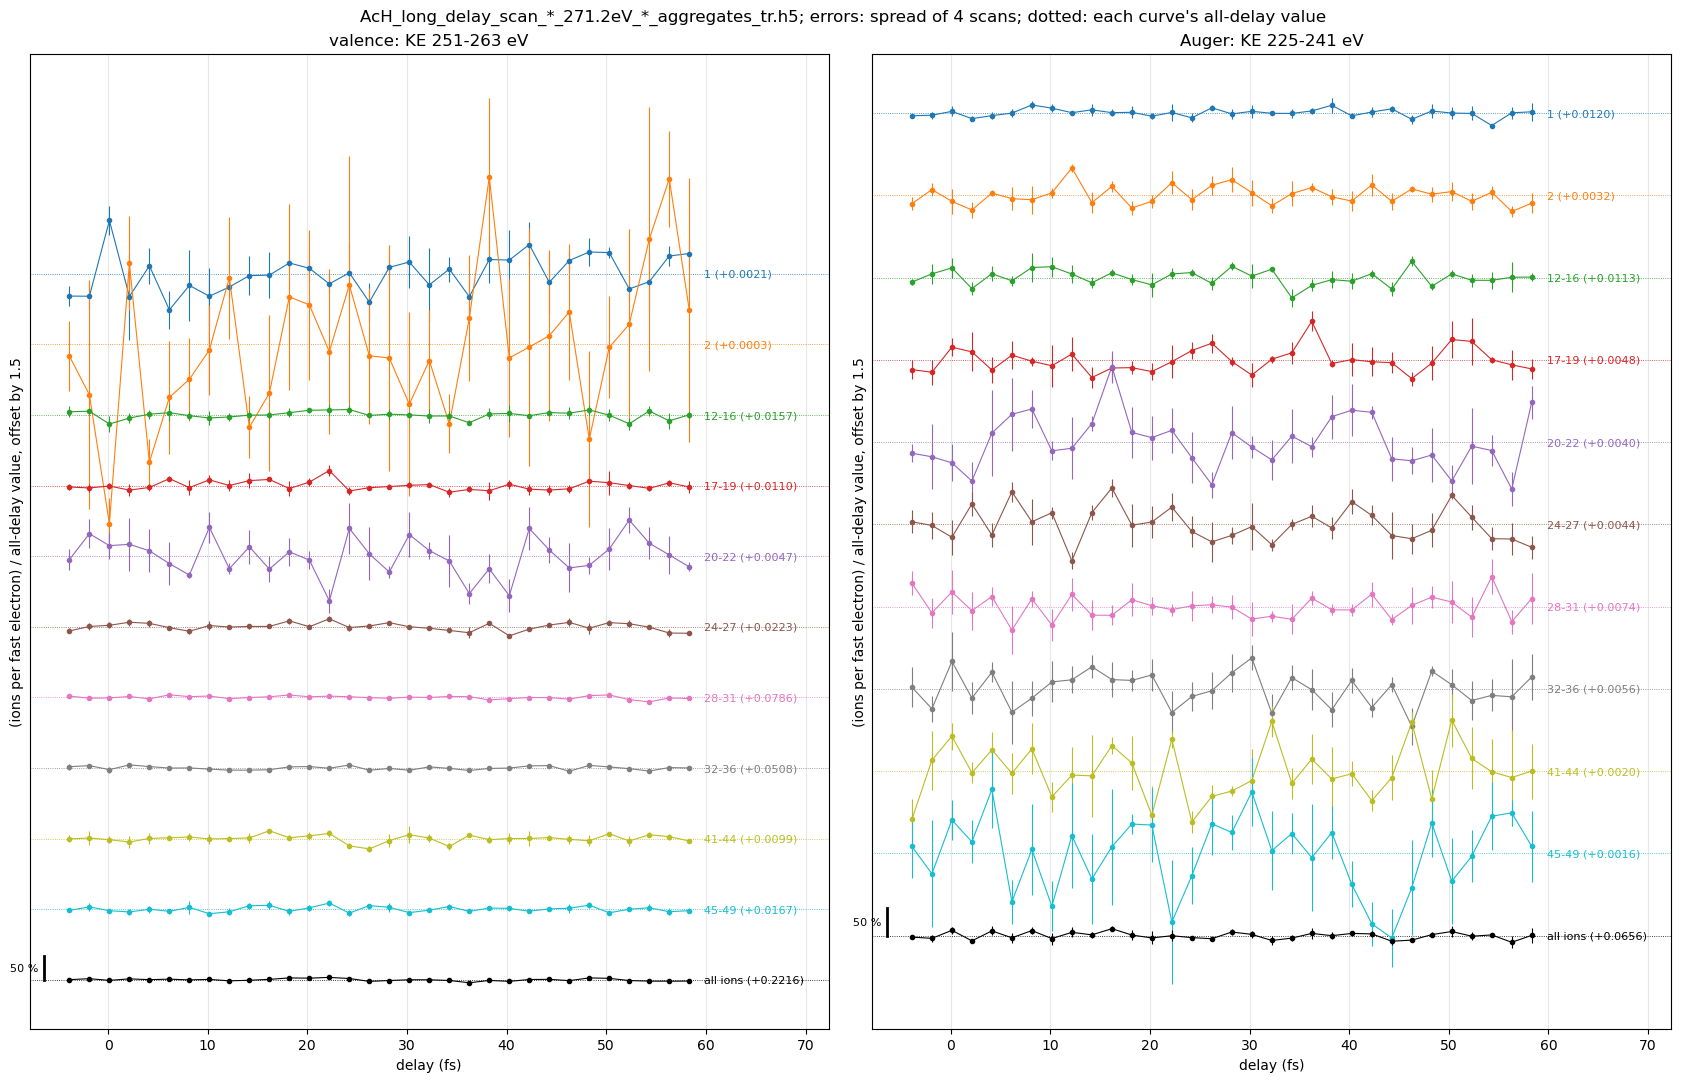

In [8]:
# Coincident ions per fast electron against delay, each range relative to its all-delay value
sel = [names.index(r) for r in (COINC_RANGES if COINC_RANGES is not None else names)]
pc_z = np.nansum(pcov * w8, axis=(0, 2)) / nz[None, :, None]     # (window, delay, ion TOF bin)
Ne_z = np.nansum(Ne * n[:, None], axis=(0, 2)) / nz              # (window, delay)
rng_z = (pc_z / Ne_z[..., None]) @ Wi.T                          # (window, delay, range)
nsz = n.sum(axis=1)                                              # (scan, delay)
pcsz = np.nansum(pcov * w8, axis=2) / nsz[:, None, :, None]
Nesz = np.nansum(Ne * n[:, None], axis=2) / nsz[:, None]
rng_sz = (pcsz / Nesz[..., None]) @ Wi.T                         # (scan, window, delay, range)
rng_zerr = rng_sz.std(axis=0, ddof=1) / np.sqrt(len(d["files"])) if len(d["files"]) > 1 else np.full(rng_z.shape, np.nan)

step = STACK["coinc"]
fig, axs = plt.subplots(1, nW, figsize=(8.5 * nW, 11), squeeze=False)
print(" range      " + "   ".join(f"{k}: chi2/dof vs constant" for k in E_WINDOWS))
for k, i in enumerate(sel):
    line = f" {names[i]:9s}"
    col = f"C{i % 10}" if i < i_all else "k"
    off = (len(sel) - 1 - k) * step                              # first range on top
    for w, ax in enumerate(axs[0]):
        y, e, y0 = rng_z[w, :, i], rng_zerr[w, :, i], rng_e[w, i]
        ax.errorbar(delay, y / y0 + off, e / abs(y0), fmt="o-", ms=3, lw=0.8, color=col)
        ax.axhline(1 + off, color=col, lw=0.6, ls=":")
        ax.text(delay[-1] + 1.5, 1 + off, f"{names[i]} ({y0:+.4f})", color=col, va="center", fontsize=8)
        line += f"   {chi2_const(y, e):8.2f}                 "
    print(line)
for w, (ax, k) in enumerate(zip(axs[0], E_WINDOWS)):
    ax.set(xlabel="delay (fs)", xlim=(delay[0] - 4, delay[-1] + 14), yticks=[],
           ylabel=f"(ions per fast electron) / all-delay value, offset by {step}",
           title=f"{k}: KE {d['ke_windows'][w][0]:.0f}-{d['ke_windows'][w][1]:.0f} eV")
    scale_bar(ax, delay[0] - 2.5, 0.5, "50 %")
fig.suptitle(f"{SCANS}; errors: spread of {len(d['files'])} scans; dotted: each curve's all-delay value")
fig.tight_layout()
plt.show()

## 5. All photon energies
For each entry of `ENERGY_SCANS` (scans pooled): top, the fraction of all ions of each range; bottom, all ions per
`MONITOR`; each relative to its all-delay value. The table gives χ²/dof of a delay-independent fraction.

 photon E   scans   shots             1       2   12-16   17-19   20-22   24-27   28-31   32-36   41-44   45-49   (chi2/dof, fraction vs delay)
 268.2 eV     4     9683215      2.05    1.09    1.40    0.80    2.43    1.04    0.93    2.05    1.02    1.24
 269.7 eV     4     9822723      1.59    1.23    0.69    0.98    1.10    1.39    1.04    1.03    0.92    0.78
 271.2 eV     4     9845664      1.24    0.63    1.19    1.06    0.71    1.29    1.03    1.09    0.59    1.44
 272.7 eV     4     9784336      1.46    1.15    0.84    0.65    0.93    0.81    1.19    0.90    1.61    0.68
 274.2 eV     3     7339432      1.01    1.34    1.19    1.43    1.32    1.33    1.25    0.75    0.98    1.23


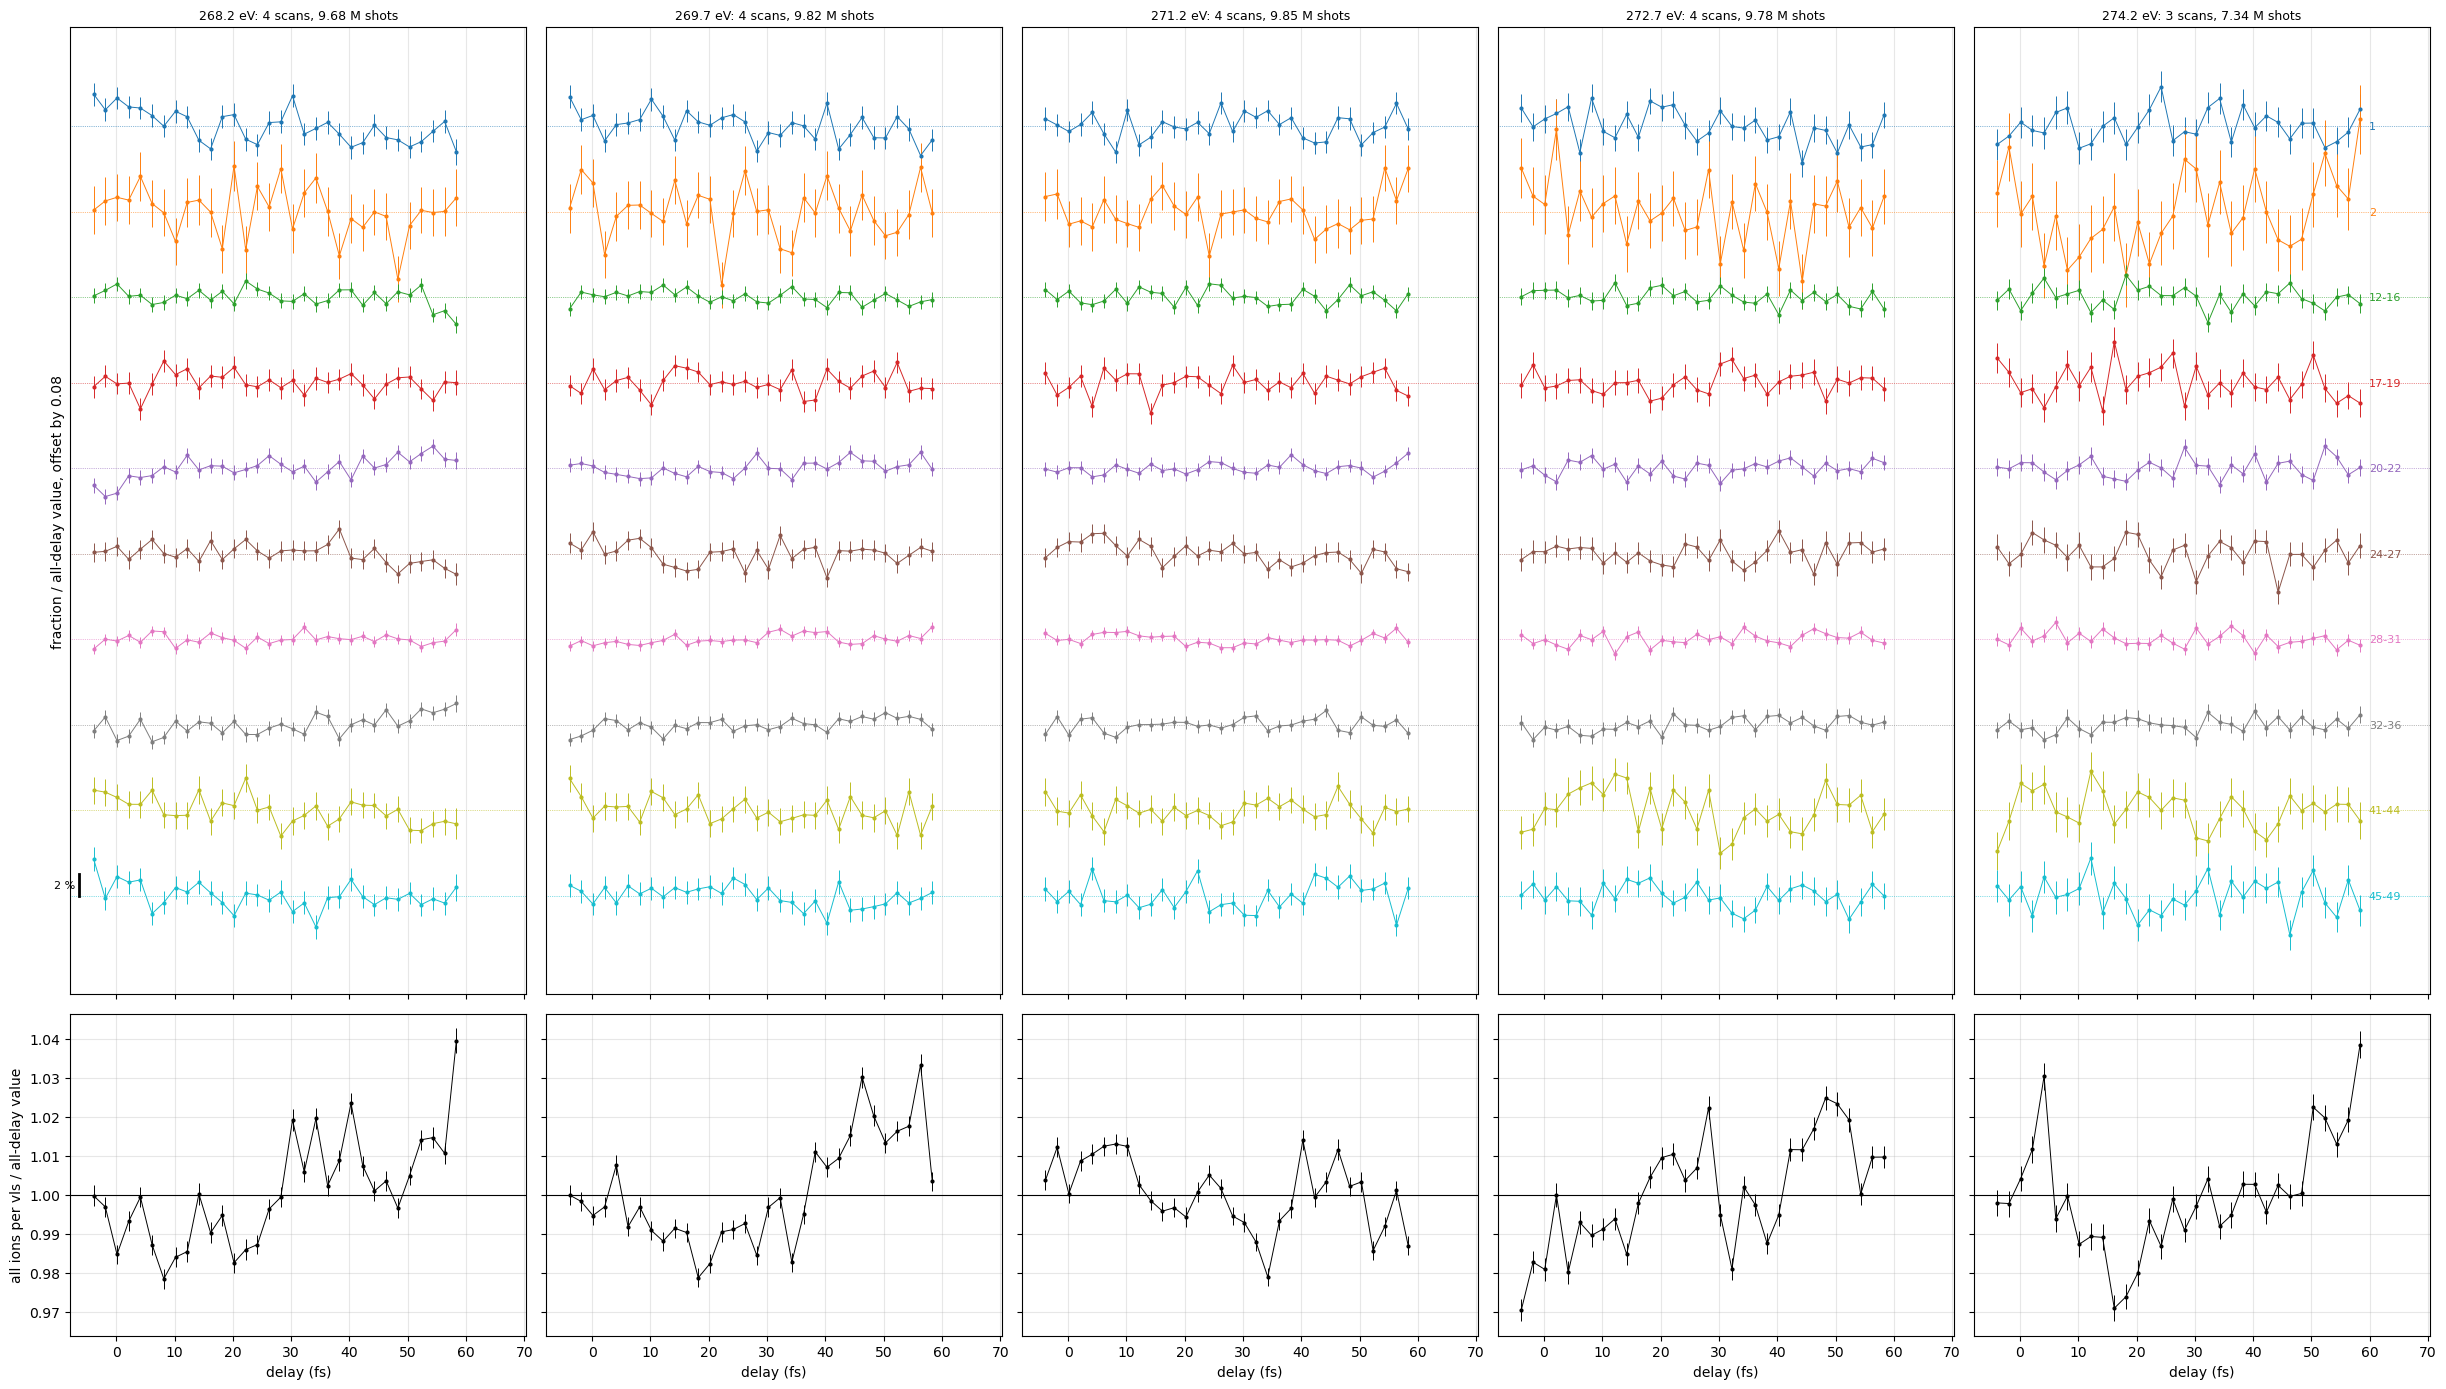

In [9]:
sets = {}
for lab, pat in ENERGY_SCANS.items():
    try:
        sets[lab] = load_set(pat)
    except FileNotFoundError as err:
        print(err)
step = STACK["yield"]
fig, axs = plt.subplots(2, len(sets), figsize=(4.6 * len(sets) + 1.5, 14), sharex=True, sharey="row", squeeze=False,
                        gridspec_kw={"height_ratios": [3, 1]})
print(" photon E   scans   shots      " + "".join(f"{r:>8s}" for r in names[:-1]) + "   (chi2/dof, fraction vs delay)")
for j, (lab, ds) in enumerate(sets.items()):
    Yz_, Sz_, nz_, Ya_, Sa_, na_ = delay_moments(ds)
    chis = []
    for i in range(R - 1):
        f_, fe = ratio(i, i_all, Yz_, Sz_, nz_)
        f0 = Ya_[i] / Ya_[i_all]
        off = (R - 2 - i) * step                                 # first range on top
        axs[0, j].errorbar(ds["delay"], f_ / f0 + off, fe / f0, fmt="o-", ms=2, lw=0.7, color=f"C{i % 10}")
        axs[0, j].axhline(1 + off, color=f"C{i % 10}", lw=0.5, ls=":")
        if j == len(sets) - 1:
            axs[0, j].text(ds["delay"][-1] + 1.5, 1 + off, names[i], color=f"C{i % 10}", va="center", fontsize=8)
        chis.append(chi2_const(f_, fe))
    y, e = per_monitor(i_all, Yz_, Sz_, nz_)
    y0 = per_monitor(i_all, Ya_, Sa_, na_)[0]
    axs[1, j].errorbar(ds["delay"], y / y0, e / y0, fmt="ko-", ms=2, lw=0.7)
    axs[1, j].axhline(1, color="k", lw=0.8)
    axs[0, j].set_title(f"{lab}: {len(ds['files'])} scans, {ds['n'].sum() / 1e6:.2f} M shots", fontsize=9)
    axs[1, j].set_xlabel("delay (fs)")
    print(f" {lab:9s}  {len(ds['files']):3d}   {ds['n'].sum():9d}  " + "".join(f"{c:8.2f}" for c in chis))
d0 = next(iter(sets.values()))["delay"]
axs[0, 0].set(xlim=(d0[0] - 4, d0[-1] + 12), yticks=[], ylabel=f"fraction / all-delay value, offset by {step}")
scale_bar(axs[0, 0], d0[0] - 2.5, 0.02, "2 %")
axs[1, 0].set_ylabel(f"all ions per {MONITOR} / all-delay value")
fig.tight_layout()
plt.show()